# ❤️ Heart Disease Prediction using Machine Learning

**Goal:** predict whether a patient has heart disease from 13 clinical measurements, compare five classifiers, tune the best one and save a ready-to-use model.

**Dataset:** Cleveland Heart Disease data (UCI Machine Learning Repository) — 297 patients, 13 features, binary target `condition` (0 = no disease, 1 = disease).

**Workflow:** load & inspect → EDA → train/test split → model comparison (hold-out **and** 5-fold CV) → hyperparameter tuning → evaluation → feature importance → save model.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

# Paths are relative to this notebook (notebooks/), so it runs the same on any machine.
DATA_PATH = Path("../data/heart_cleveland_upload.csv")
IMAGES = Path("../images")
MODELS = Path("../models")
IMAGES.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(IMAGES / f"{name}.png", dpi=130, bbox_inches="tight")

## 2. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [3]:
print("Missing values :", int(df.isnull().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
df.describe().T.round(2)

Missing values : 0
Duplicate rows : 0


,count,mean,std,min,25%,50%,75%,max
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,297.0,2.16,0.96,0.0,2.0,2.0,3.0,3.0
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0
restecg,297.0,1.00,0.99,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2


### Feature dictionary

| Feature | Meaning | Type |
|---|---|---|
| `age` | Age in years | numeric |
| `sex` | 1 = male, 0 = female | categorical |
| `cp` | Chest pain type (0–3) | categorical |
| `trestbps` | Resting blood pressure (mm Hg) | numeric |
| `chol` | Serum cholesterol (mg/dl) | numeric |
| `fbs` | Fasting blood sugar > 120 mg/dl | categorical |
| `restecg` | Resting ECG result (0–2) | categorical |
| `thalach` | Maximum heart rate achieved | numeric |
| `exang` | Exercise-induced angina | categorical |
| `oldpeak` | ST depression induced by exercise | numeric |
| `slope` | Slope of the peak exercise ST segment | categorical |
| `ca` | Major vessels coloured by fluoroscopy (0–3) | categorical |
| `thal` | Thalassemia test result | categorical |
| `condition` | **Target** – heart disease present | binary |

In [4]:
TARGET = "condition"
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X = df.drop(columns=TARGET)
y = df[TARGET]
print(f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical = {X.shape[1]} features")

5 numeric + 8 categorical = 13 features


## 3. Exploratory data analysis

### 3.1 Target balance

condition
0    53.9
1    46.1


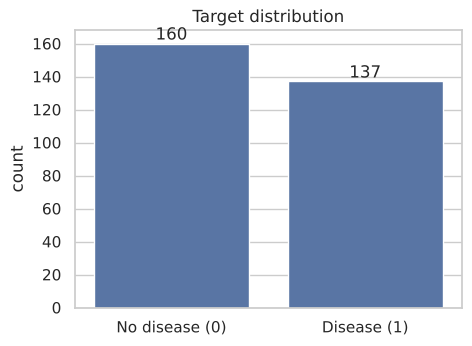

In [5]:
counts = y.value_counts().sort_index()
print((y.value_counts(normalize=True).sort_index() * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(5, 3.6))
sns.countplot(x=y, ax=ax)
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_xlabel("")
ax.set_title("Target distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
save_fig("01_target_distribution")
plt.show()

The classes are fairly balanced (54% / 46%), so accuracy is a reasonable headline metric; we still report precision, recall, F1 and ROC-AUC.

### 3.2 Numeric features

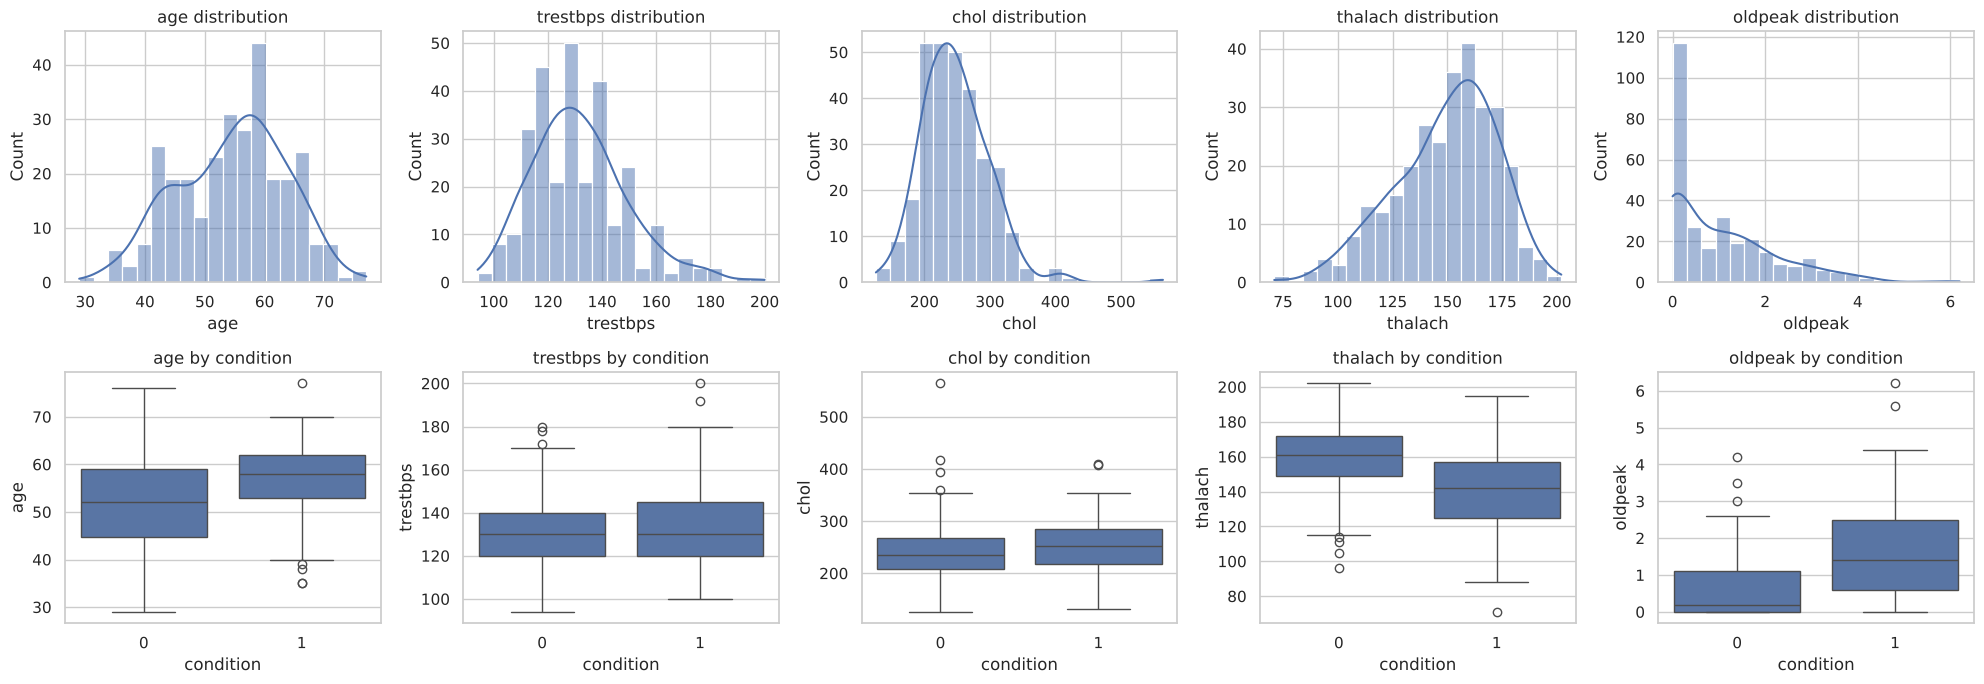

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, col in enumerate(NUMERIC):
    sns.histplot(df[col], kde=True, bins=20, ax=axes[0, i])
    axes[0, i].set_title(f"{col} distribution")
    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by condition")
plt.tight_layout()
save_fig("02_numeric_features")
plt.show()

Patients with heart disease tend to be older, reach a **lower maximum heart rate** (`thalach`) and show a higher ST depression (`oldpeak`).

### 3.3 Categorical features

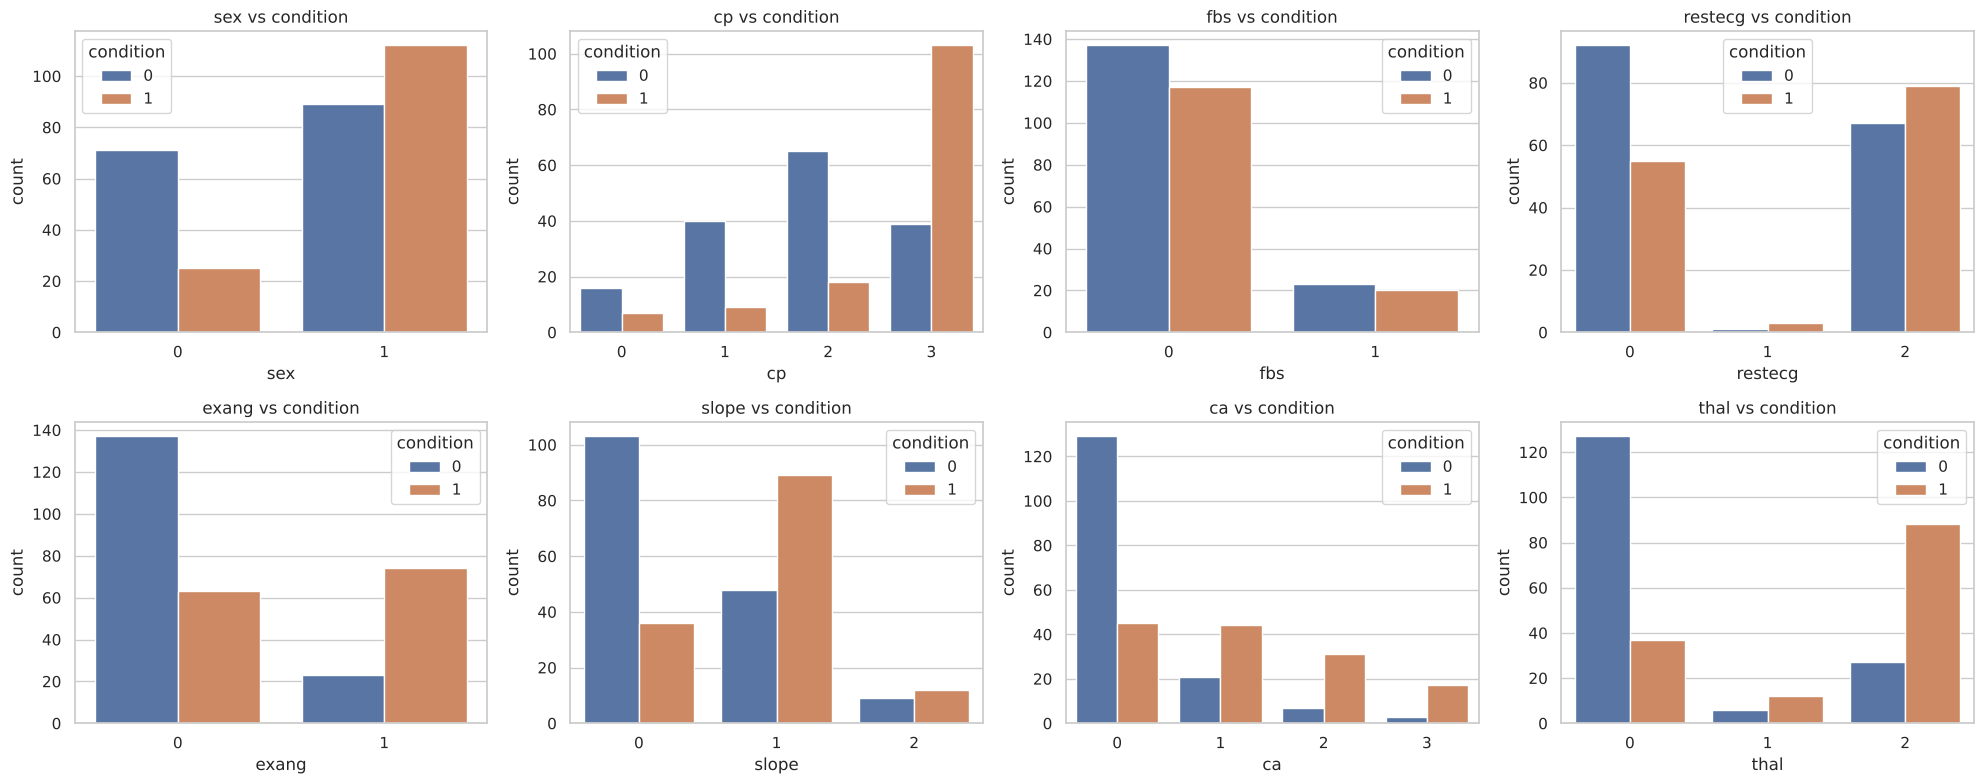

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), CATEGORICAL):
    sns.countplot(data=df, x=col, hue=TARGET, ax=ax)
    ax.set_title(f"{col} vs condition")
plt.tight_layout()
save_fig("03_categorical_features")
plt.show()

Disease is much more common with chest-pain type 3 (`cp`), exercise-induced angina (`exang`), more blocked vessels (`ca`) and abnormal thalassemia results (`thal`).

### 3.4 Correlations

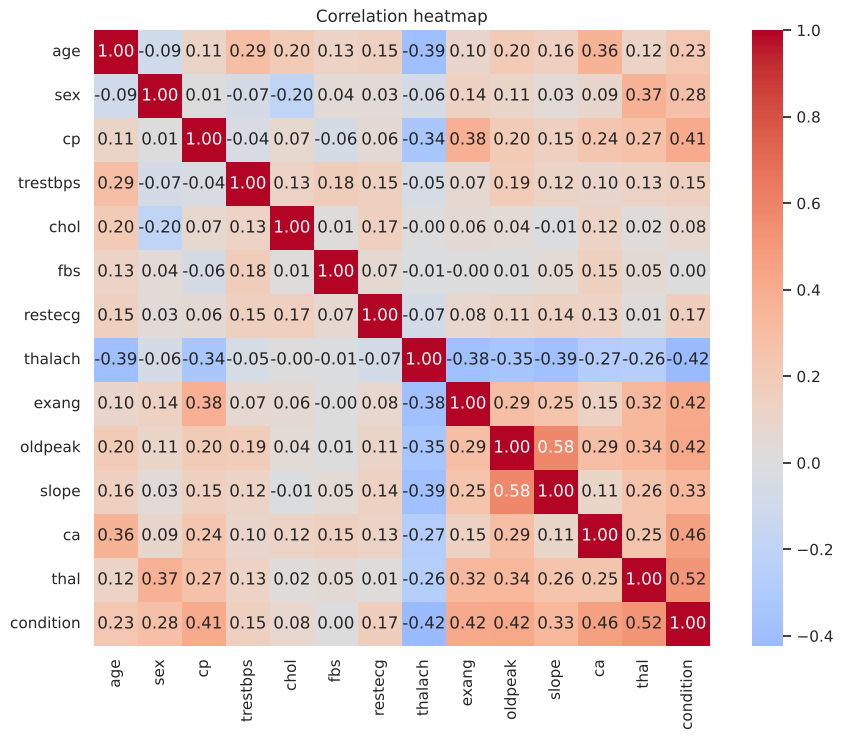

thal        0.52
ca          0.46
oldpeak     0.42
exang       0.42
cp          0.41
slope       0.33
sex         0.28
age         0.23
restecg     0.17
trestbps    0.15
chol        0.08
fbs         0.00
thalach    -0.42
Name: condition, dtype: float64

In [8]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
save_fig("04_correlation_heatmap")
plt.show()

df.corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(2)

## 4. Train / test split

An 80/20 **stratified** split keeps the class ratio equal in both sets. The scaler is part of a `Pipeline`, so it is fitted on training data only — no information leaks from the test set.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train disease rate:", round(y_train.mean(), 3), "| Test disease rate:", round(y_test.mean(), 3))

Train: (237, 13) | Test: (60, 13)
Train disease rate: 0.46 | Test disease rate: 0.467


## 5. Model comparison

Five classifiers, each wrapped in `StandardScaler → model`. With only 60 test patients a single split is noisy (one patient ≈ 1.7 percentage points), so models are ranked by **5-fold cross-validated accuracy on the training set** and the hold-out test set is used for the final report.

In [10]:
def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    pipe = make_pipeline(model)
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "CV Accuracy": cv_scores.mean(),
        "CV Std": cv_scores.std(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("CV Accuracy", ascending=False)
results.round(3)

,CV Accuracy,CV Std,Test Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,,,
Logistic Regression,0.823,0.053,0.917,1.000,0.821,0.902,0.953
SVM,0.790,0.068,0.900,1.000,0.786,0.880,0.940
KNN,0.769,0.060,0.900,1.000,0.786,0.880,0.959
Random Forest,0.768,0.043,0.883,0.957,0.786,0.863,0.945
Decision Tree,0.735,0.058,0.783,0.800,0.714,0.755,0.779


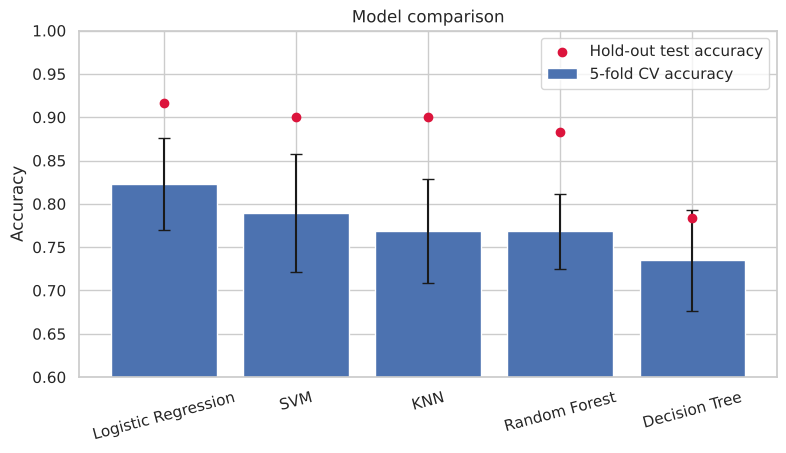

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = results.index
ax.bar(order, results["CV Accuracy"], yerr=results["CV Std"], capsize=4, label="5-fold CV accuracy")
ax.scatter(order, results["Test Accuracy"], color="crimson", zorder=3, label="Hold-out test accuracy")
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("Model comparison")
ax.legend(loc="upper right")
plt.xticks(rotation=15)
save_fig("05_model_comparison")
plt.show()

In [12]:
best_name = results["CV Accuracy"].idxmax()
print("Best model by cross-validation:", best_name)

Best model by cross-validation: Logistic Regression


## 6. Hyperparameter tuning

The best model is tuned with `GridSearchCV` (5-fold, training set only). The search optimises **ROC-AUC** rather than accuracy: it is threshold-free and less noisy on a small dataset, and it avoids rewarding over-regularised models that simply predict the majority class more often.

In [13]:
pipe = make_pipeline(LogisticRegression(solver="liblinear", random_state=RANDOM_STATE))
param_grid = {
    "model__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 100],
    "model__penalty": ["l1", "l2"],
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters      :", grid.best_params_)
print(f"Best CV ROC-AUC      : {grid.best_score_:.4f}")

Best parameters      : {'model__C': 0.1, 'model__penalty': 'l1'}
Best CV ROC-AUC      : 0.8963


In [14]:
untuned = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)).fit(X_train, y_train)
tuned = grid.best_estimator_

comparison = pd.DataFrame({
    "Model": ["Untuned", "Tuned"],
    "CV ROC AUC": [cross_val_score(untuned, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
                   grid.best_score_],
    "Test Accuracy": [accuracy_score(y_test, untuned.predict(X_test)),
                      accuracy_score(y_test, tuned.predict(X_test))],
    "Test ROC AUC": [roc_auc_score(y_test, untuned.predict_proba(X_test)[:, 1]),
                     roc_auc_score(y_test, tuned.predict_proba(X_test)[:, 1])],
}).set_index("Model")
comparison.round(3)

,CV ROC AUC,Test Accuracy,Test ROC AUC
Model,,,
Untuned,0.876,0.917,0.953
Tuned,0.896,0.900,0.912


> **Honest note:** tuning (L1 penalty, `C = 0.1`) improves the *cross-validated* ROC-AUC (0.876 → 0.896) and gives a **sparser**, easier-to-interpret model (several coefficients shrink to exactly zero), but the hold-out scores are slightly lower. With only 60 test patients that gap is within noise (one patient ≈ 1.7 percentage points), so the tuned model is kept because it was chosen by cross-validation, not by looking at the test set.

## 7. Final evaluation on the held-out test set

              precision    recall  f1-score   support

  No disease       0.84      1.00      0.91        32
     Disease       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60



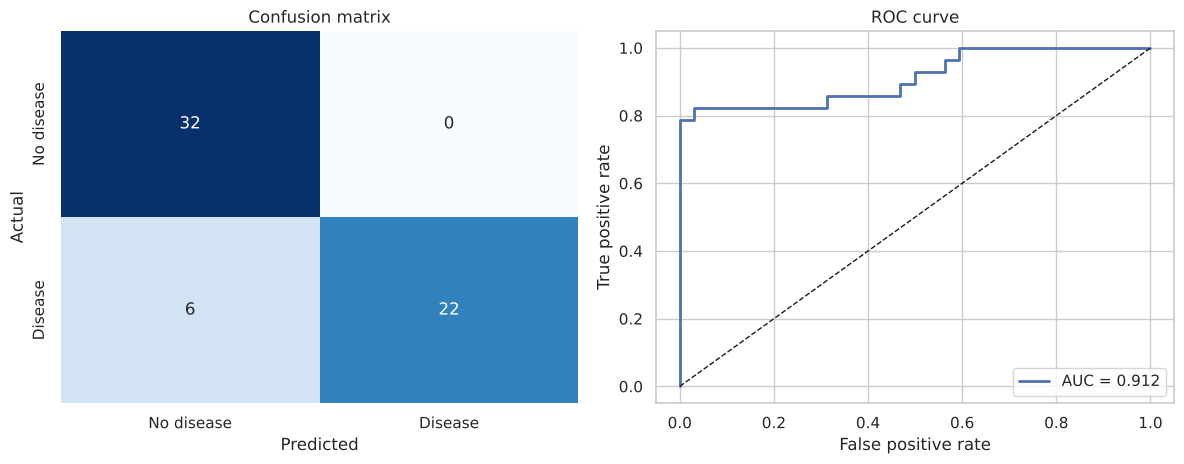

In [15]:
y_pred = tuned.predict(X_test)
y_prob = tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
plt.tight_layout()
save_fig("06_confusion_matrix_roc")
plt.show()

In a medical setting **recall** (catching every sick patient) matters most: a false negative is a missed diagnosis. Check the recall for the *Disease* class above before using this model for anything beyond learning.

## 8. Feature importance

For logistic regression on standardised inputs, the coefficient size shows how strongly each feature pushes the prediction (positive → more likely disease). The L1 penalty has shrunk several features to exactly zero, i.e. the model does not need them.

,Feature,Coefficient
0,ca,0.628
1,thal,0.490
2,oldpeak,0.393
3,thalach,-0.300
4,exang,0.287
5,cp,0.269
6,sex,0.005
7,age,0.000
8,trestbps,0.000
9,chol,0.000


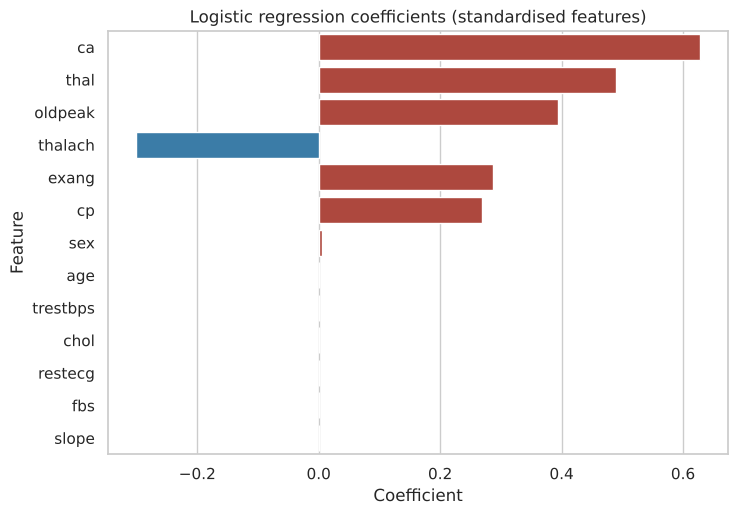

In [16]:
coefs = tuned.named_steps["model"].coef_[0]
importance = (pd.DataFrame({"Feature": X.columns, "Coefficient": coefs})
              .assign(Abs=lambda d: d["Coefficient"].abs())
              .sort_values("Abs", ascending=False)
              .drop(columns="Abs")
              .reset_index(drop=True))
display(importance.round(3))

plt.figure(figsize=(8, 5.5))
sns.barplot(data=importance, x="Coefficient", y="Feature",
            palette=["#c0392b" if c > 0 else "#2980b9" for c in importance["Coefficient"]])
plt.title("Logistic regression coefficients (standardised features)")
save_fig("07_feature_importance")
plt.show()

## 9. Save the model

In [17]:
MODEL_PATH = MODELS / "heart_disease_model.joblib"
joblib.dump(tuned, MODEL_PATH)

# Reload and confirm it reproduces the same predictions on raw (unscaled) input.
reloaded = joblib.load(MODEL_PATH)
assert (reloaded.predict(X_test) == tuned.predict(X_test)).all()
print(f"Saved {MODEL_PATH} and verified it reloads correctly.")

Saved ../models/heart_disease_model.joblib and verified it reloads correctly.


## 10. Conclusion

* Five classifiers were compared with both a stratified hold-out split and 5-fold cross-validation; **Logistic Regression** gave the best cross-validated accuracy and was then tuned with `GridSearchCV`.
* The saved model is a single `Pipeline` (scaler + classifier), so it accepts raw patient values directly — see `predict.py`.
* The model relies mainly on the number of blocked major vessels (`ca`), thalassemia result (`thal`), ST depression (`oldpeak`), maximum heart rate (`thalach`, protective), exercise-induced angina (`exang`) and chest-pain type (`cp`).
* Hold-out performance is about 90% accuracy with perfect precision but ~79% recall on the *Disease* class — it still misses some sick patients, which matters for any screening use.
* **Limitations:** only 297 patients from one clinic, so results may not generalise; this is an educational project and **not a medical device**.